# Module 5 — Worksheet 4: Bagging and Random Forests

**ISA 591 — Introduction to Data Mining in Business**  
**Goal:** Understand how combining many trees can improve predictions, and implement bagging and random forests with straightforward Python code.

Follow the cells in order. **Run** the provided examples, complete the short **TODO** exercises, and write your interpretations in the Markdown cells. We will use the same **Telco customer churn** data throughout.

**Learning goals:** bootstrap sampling with replacement; voting versus probability averaging; compare a single tree, bagging and random forests; examine out-of-bag performance and variable importance.

## 1. Why use an ensemble of trees?

A single decision tree can be sensitive to the observations used for fitting. **Ensemble learning** combines predictions from several trees.

- **Classification:** trees can vote for a class; probabilities can also be averaged.
- **Regression:** tree predictions are typically averaged.
- **Bagging:** fit trees to different bootstrap samples (random samples **with replacement**).
- **Random forest:** adds random selection of candidate predictors at each split.

**Practice 1A:** Three trees predict customer spending of $82, $96, and $91. What is their average prediction?

In [1]:
import numpy as np


## Suppose y = Customer spending

#### 1 single decision tree (regression tree)
#### fit(X_train, y_train) ---> $82
#### actual = $90 
#### bias^2 = (82 - 90)^2 = 64  (generally the bias is good on the training) 
#### variance: very high on decision trees (if X_train changes the tree fit changes a lot)


#### 3 decision trees (regression trees)
#### get a prediction for each one them
#### how can I get a different prediction for each tree?
####### take a bootstrap sample (BOOTSTRAP AGGREGATING - BAGGING)
####### fit(X_train_B1, y_train_B1) ---> $82
####### fit(X_train_B2, y_train_B2) ---> $96
####### fit(X_train_B3, y_train_B3) ---> $91
predictions = np.array([82, 96, 91])

# TODO: calculate the average prediction
average_prediction = np.mean(predictions)
print('Ensemble prediction:', average_prediction)

Ensemble prediction: 89.66666666666667


In [2]:
## What is bootstrap sampling?
#### sampling with replacement 
obs = np.arange(10) 
obs

print(f'A bootstrap sample: {np.random.choice(obs, size=3, replace=True)}')  ## duplicates are possible
print(f'A regular sample: {np.random.choice(obs, size=3, replace=False)}')   ## obs are different, no duplicates

A bootstrap sample: [7 5 1]
A regular sample: [6 0 5]


In [3]:
## why do we want to use bootstrap sampling?
#### we can use the same sample size as the original training set
#### some obs are repeated, while some others are not included in the bootstrap sample
#### obs NOT included are called "Out-of-bag" (OOB) obs
print(f'A bootstrap sample: {np.random.choice(obs, size=10, replace=True)}')

A bootstrap sample: [9 9 3 6 6 4 1 2 8 7]


In [ ]:
## OOB obs can be used to estimate the error of the model (instead of using a test set)

## 2. Bootstrap sampling

With replacement means the **same row can be chosen more than once** and some rows are not chosen. Unselected observations are called **out-of-bag (OOB)** for that bootstrap sample.

In [4]:
import pandas as pd

customers = pd.DataFrame({'Customer': [1, 2, 3, 4, 5, 6, 7, 8]})
bootstrap = customers.sample(n=8, replace=True, random_state=591)

print('Original customers:')
print(customers.T)
print()
print('Bootstrap sample:')
print(bootstrap.T)

Original customers:
          0  1  2  3  4  5  6  7
Customer  1  2  3  4  5  6  7  8

Bootstrap sample:
          3  2  5  6  5  7  4  4
Customer  4  3  6  7  6  8  5  5


In [ ]:
## OOB samples (1,2)

**Practice 2A:** Which customer numbers were repeated? Which customer numbers were not selected? Use `unique()` and `isin()` to help you, or simply inspect the printed sample.

**Your answer:**

- Repeated:
- Not selected (OOB):

In [5]:
# TODO: list the customers not selected in the bootstrap sample
# Hint: ~customers['Customer'].isin(bootstrap['Customer'])
## repeated obs = 5,6

~customers['Customer'].isin(bootstrap['Customer'])

oob_customers = customers.loc[ ~customers['Customer'].isin(bootstrap['Customer']) , 'Customer']
print(oob_customers.tolist())

[1, 2]


## 3. Load and prepare Telco customer churn data

**Business question:** Can we predict which telecommunications customers will leave (`Churn = Yes`)?

We use the same simple sequence as the other tree worksheets: **read → clean → encode → split → fit → evaluate**. No custom functions or preprocessing pipelines are necessary for this introductory exercise.

In [6]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Read data (GitHub first; a downloaded CSV can be used if offline)
url = 'https://raw.githubusercontent.com/martinwg/ISA591/refs/heads/main/data/Telco_Churn.csv'
df = pd.read_csv(url)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
# Fix TotalCharges: some entries are blank or stored as text
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Drop identifier (it should not be a predictor)
df = df.drop(columns=['customerID'])

# Target: 1 = churn, 0 = no churn
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Dummy-encode the categorical predictors
df = pd.get_dummies(df, drop_first=True, dtype=int)

df.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [8]:
# Create predictors and target
X = df.drop('Churn', axis=1)
y = df['Churn']

# Split 80% training / 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=591, stratify=y
)

print('Training set:', X_train.shape)
print('Test set:', X_test.shape)
print('Churn rate:', y.mean().round(3))

Training set: (5634, 30)
Test set: (1409, 30)
Churn rate: 0.265


In [ ]:
from sklearn.preprocessing import StandardScaler

## INSTANCE
sc = StandardScaler()

## fit
sc.fit(X_train)
sc.transfor(X_test)

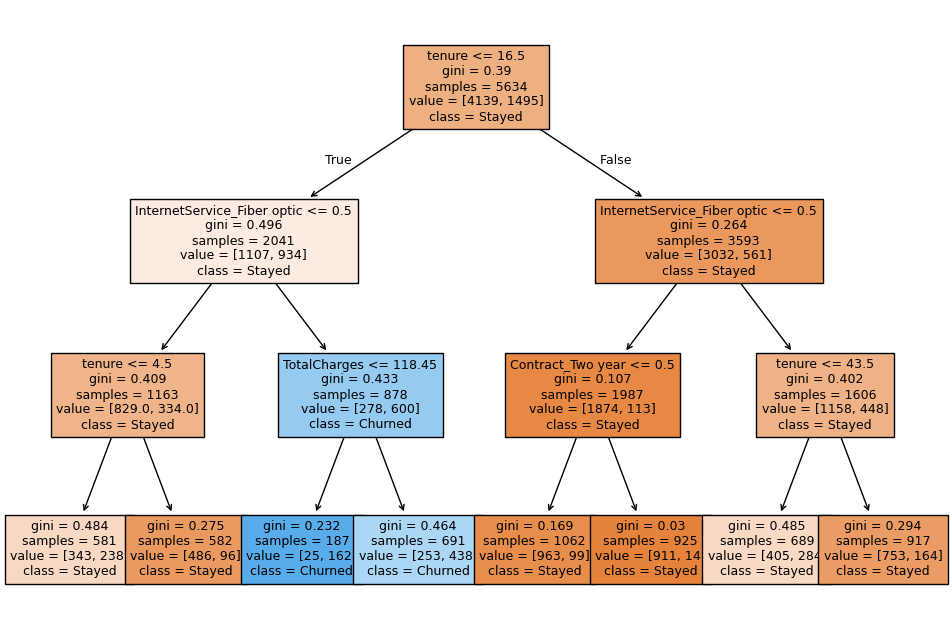

In [9]:
## training and test set
### LET'S FIT 1 SINGLE DECISION TREE

dt = DecisionTreeClassifier(max_depth=3, random_state=591)

### fit on training set
dt.fit(X_train, y_train)

### predict on test set
y_pred = dt.predict(X_test)

### accuracy
accuracy_score(y_test, y_pred)

### plot the tree
plt.figure(figsize=(12, 8))
plot_tree(dt, feature_names=X.columns, class_names=['Stayed', 'Churned'], filled=True, fontsize=9);

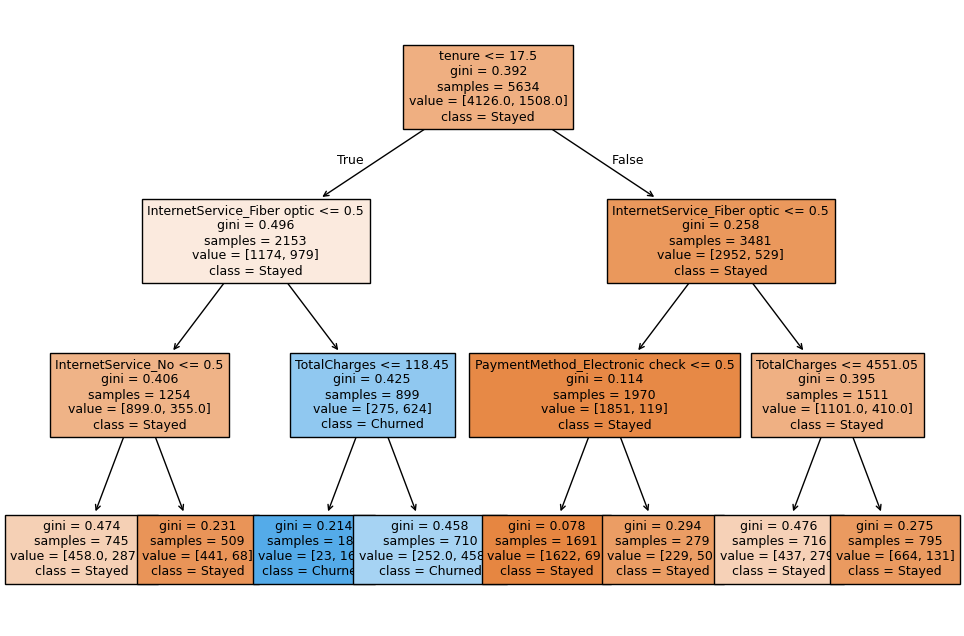

In [12]:
## IDEA: OF BAGGING

## create multiple boostrap samples
#### BOOSTRAP SAMPLE 1
X_train_b1, y_train_b1 = X_train.sample(n=len(X_train), replace=True, random_state=2), y_train.sample(n=len(y_train), replace=True, random_state=2)


### FIT ON BOOSTRAP SAMPLE 1
dt_b1 = DecisionTreeClassifier(max_depth=3, random_state=591)
dt_b1.fit(X_train_b1, y_train_b1)

### DON'T NEED TO PREDICT ON THE TEST SET (we can use OOB obs)

## THEN WE REPEAT THIS MULTIPLE TIMES (e.g., 100 times) TO CREATE AN ENSEMBLE OF DECISION TREES

### plot the tree
plt.figure(figsize=(12, 8))
plot_tree(dt_b1, feature_names=X.columns, class_names=['Stayed', 'Churned'], filled=True, fontsize=9);

In [16]:
## We can use sklearn.ensemble.BaggingClassifier to do this automatically

from sklearn.ensemble import BaggingClassifier

## instance
#### estimator: the model you want to ensemble (e.g., DecisionTreeClassifier)
#### n_estimators: number of boostrap samples (and trees) to create
#### random_state: seed for each tree (reproducibility)
#### oob_score: you want an OOB score (accuracy)
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=4, random_state=591),
    n_estimators=50,
    random_state=591,
    oob_score=True
)

## fit on training set
bagging.fit(X_train, y_train)

## OOB score
print('OOB score:', bagging.oob_score_)

OOB score: 0.7953496627618033


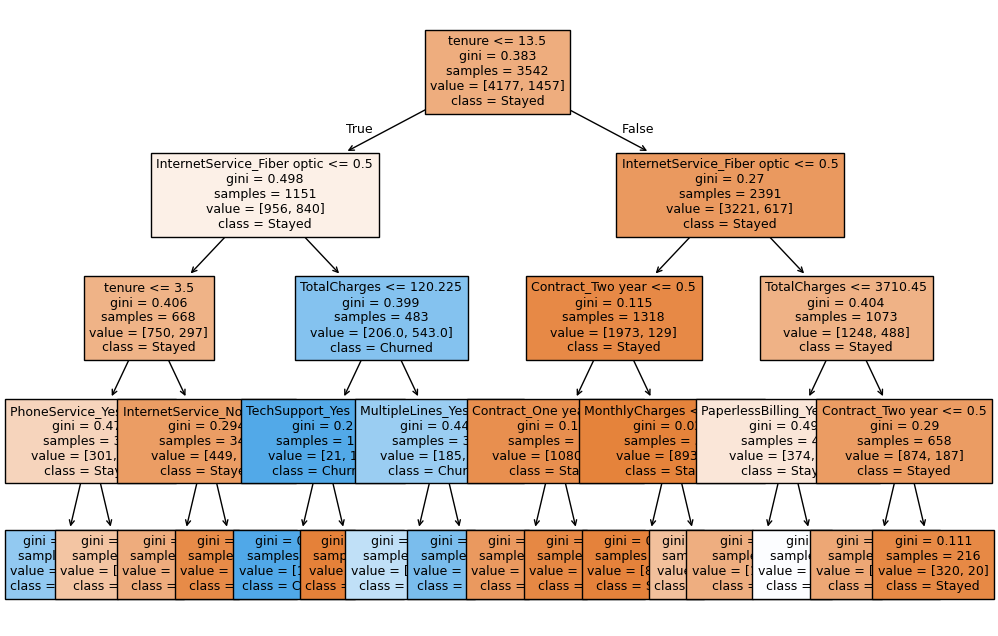

In [17]:
## can we plot the ensemble?
#### no, because it is a colllection of trees
#### but, you can the individual trees
bagging.estimators_[2]  ## tree number 1 

plt.figure(figsize=(12, 8))
plot_tree(bagging.estimators_[0], feature_names=X.columns, class_names=['Stayed', 'Churned'], filled=True, fontsize=9);


In [18]:
### How are trees different every time in a bagging ensemble?
#### we use a different bootstrap on each one 

### is a guaranteed that each tree is different?
#### no, because samples are random

### what is the sample size of each bootstrap sample?
##### same as the orginal? max_samples by default is 100% of original training set size
##### bagging = BaggingClassifier(max_samples = 0.05) takes only 5% of the original training (say you have millions of obs)

### is bagging better than a single decision tree?
#### it usually is, not guaranteed

## 4. Fit one decision tree (benchmark)

A single tree gives us a model to compare against an ensemble. We restrict its depth so it is readable.

In [19]:
# Fit a single decision tree
dt = DecisionTreeClassifier(max_depth=3, random_state=591)
dt.fit(X_train, y_train)

print('Training accuracy:', round(dt.score(X_train, y_train), 4))
print('Test accuracy:', round(dt.score(X_test, y_test), 4))

Training accuracy: 0.7918
Test accuracy: 0.7842


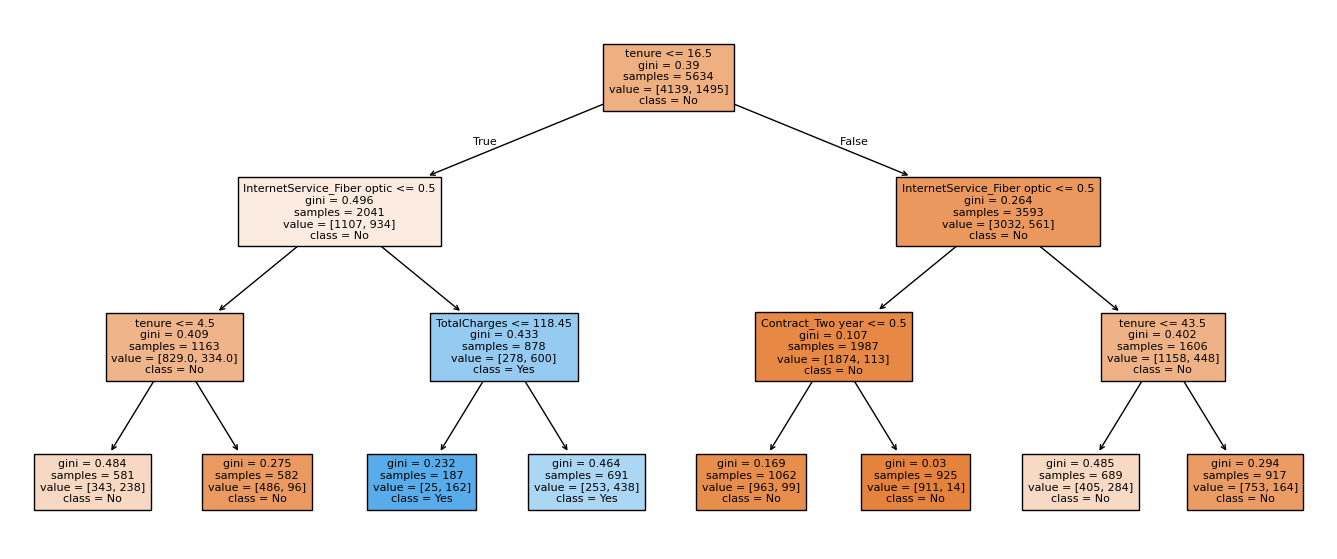

In [20]:
plt.figure(figsize=(17, 7))
plot_tree(dt, feature_names=X.columns, class_names=['No', 'Yes'],
          filled=True, fontsize=8)
plt.show()

**Practice 4A:** Trace a path from the root to a terminal node. Write one IF–THEN rule in words. Which customer characteristic appears in the first split?

**Your answer:**

## 5. Bagging: fit a small ensemble of three trees

We first fit just **three depth-1 trees** so we can look at every tree. Bagging uses a new bootstrap sample for each tree. In `scikit-learn`, the `estimator` argument specifies the base tree and `n_estimators` specifies how many trees to fit.

In [21]:
from sklearn.ensemble import BaggingClassifier

# Bagging of three small decision trees
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=591),
    n_estimators=3,
    random_state=591
)

bag.fit(X_train, y_train)
print('Bagging test accuracy:', round(bag.score(X_test, y_test), 4))

Bagging test accuracy: 0.7346


### Inspect the three trees

The three trees are stored in `bag.estimators_`. These are deliberately very small so students can see the differences caused by bootstrap samples.

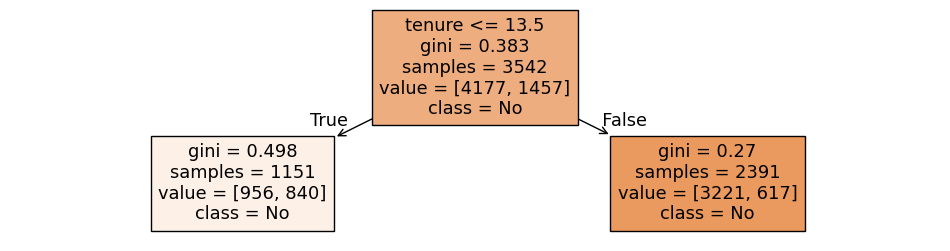

In [22]:
# Tree 1
plt.figure(figsize=(12, 3))
plot_tree(bag.estimators_[0], feature_names=X.columns,
          class_names=['No', 'Yes'], filled=True)
plt.show()

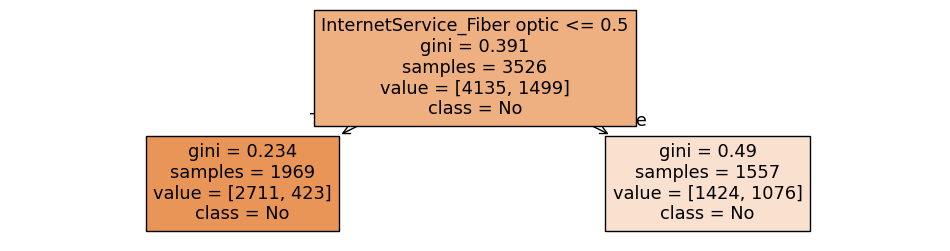

In [23]:
# Tree 2
plt.figure(figsize=(12, 3))
plot_tree(bag.estimators_[1], feature_names=X.columns,
          class_names=['No', 'Yes'], filled=True)
plt.show()

**Practice 5A:** Complete the code to plot the third tree. Do the trees all split on the same predictor? Why might they differ?

In [24]:
# TODO: plot Tree 3 using bag.estimators_[2]
# plt.figure(figsize=(12, 3))
# plot_tree(..., feature_names=X.columns, class_names=['No','Yes'], filled=True)
# plt.show()

## 6. How does the ensemble obtain one prediction?

Each tree estimates the probability of churn for the customer. Bagging averages those probabilities to calculate the ensemble's estimated probability. For a class prediction, the averaged probability is converted to a predicted class.

In this example, every tree uses all predictors. We use `.to_numpy()` for calls to individual fitted trees because bagging supplies them NumPy arrays internally.

In [25]:
# Look at the FIRST customer in the test data
customer = X_test.iloc[[0]]

print('Tree 1 probability:', bag.estimators_[0].predict_proba(customer.to_numpy())[0, 1])
print('Tree 2 probability:', bag.estimators_[1].predict_proba(customer.to_numpy())[0, 1])
print('Tree 3 probability:', bag.estimators_[2].predict_proba(customer.to_numpy())[0, 1])

print('Bagging probability:', bag.predict_proba(customer)[0, 1])
print('Bagging class:', bag.predict(customer)[0])

Tree 1 probability: 0.1607608129233976
Tree 2 probability: 0.4304
Tree 3 probability: 0.42245557350565427
Bagging probability: 0.337872128809684
Bagging class: 0


**Practice 6A:** Compute the average of the three tree probabilities. Verify that it matches the bagging probability above (allowing for rounding).

**Practice 6B:** If two trees predict `Yes` and one predicts `No`, what is the **majority-vote** class? How can voting and averaging probabilities give different results?

In [26]:
# TODO: average the probabilities of all 3 trees for the same customer
p1 = 0.1607608129233976
p2 = 0.4304
p3 = 0.42245557350565427
avg_probability = (p1 + p2 + p3) / 3
print('Manual average:', avg_probability)

Manual average: 0.337872128809684


## 7. Bagging with more trees

Three shallow trees are useful for illustration but are not necessarily a strong predictive model. Let's use **100 trees** and compare it with our single tree.

In [27]:
bag100 = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=591),
    n_estimators=100,
    random_state=591,
    n_jobs=-1,
    oob_score=True
)

bag100.fit(X_train, y_train)

print('Single tree test accuracy:', round(dt.score(X_test, y_test), 4))
print('Bagging test accuracy:', round(bag100.score(X_test, y_test), 4))
print('Bagging OOB accuracy:', round(bag100.oob_score_, 4))

Single tree test accuracy: 0.7842
Bagging test accuracy: 0.7722
Bagging OOB accuracy: 0.7886


In [33]:
X_train.shape

(5634, 30)

In [38]:
## HYPERPARAMETER OPTIMIZATION 

#### OPTION 1: Use OOB score to determine the range or values of the top hyperparameters
#### TOP HYPERPARAMS: n_estimators (# of trees) and max_samples (fraction of the training set)

## INSTANCE
bagging_withOOB = BaggingClassifier(
    estimator = DecisionTreeClassifier(max_depth = 6),
    n_estimators=500,
    max_samples = 0.2,  ## boostrap sample fraction ()
    oob_score=True
)

## FIT
bagging_withOOB.fit(X_train, y_train)

## CHECK OOB ACCURACY
print(f'OOB Accuracy is: {bagging_withOOB.oob_score_}')

OOB Accuracy is: 0.8040468583599574


In [41]:
#### OPTION 2: Use GridSearch with Cross-Validation
from sklearn.model_selection import GridSearchCV

## GRID
grid = {
    'n_estimators': [10, 50, 100, 200, 500],
    'max_samples': [0.2, 0.5, 0.75, 1]
}

## FIT BY WRAPPING THE MODEL IN GridSearchCV
bagging_withGS = GridSearchCV(
    estimator = BaggingClassifier(estimator = DecisionTreeClassifier(max_depth = 6)), 
    param_grid=grid,
    cv = 5,
    n_jobs = -1
)

## will run 5*4 = 20 models
## fit
bagging_withGS.fit(X_train, y_train)

## BEST HYPERPARAMETER
bagging_withGS.best_params_

{'max_samples': 0.2, 'n_estimators': 200}

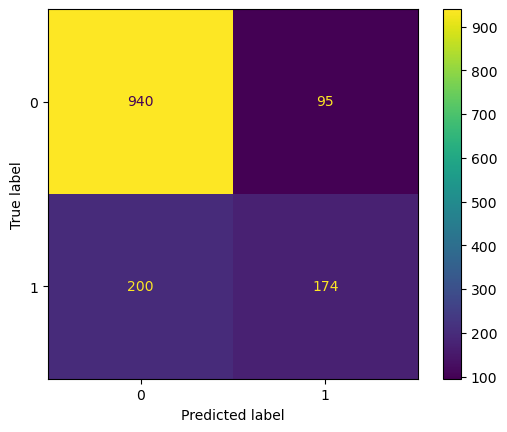

In [42]:
## Without peaking into the test set we found that max_samples = 0.2 and 200 trees is the best for Bagging
y_hat = bagging_withGS.predict(X_test)

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_hat)).plot()

**Practice 7A:** Does bagging improve test accuracy compared with our shallow tree? Does that mean bagging always performs better? What does **OOB** mean here?

**Your answer:**

In [ ]:
## The grid search returned max_samples = 0.2, and 200 trees
#### For each of those 200 trees, how many obs were they fit on?
## 20% of obs of the training
0.2*X_train.shape[0]

## is each observation unique? 1127
## NO, E.G., customer could be selected many times or NOT AT ALL

## COuld we be overfitting?
#### yes, the smaller max_samples is the more likely overfitting is

## How many variables does each tree use?
## all 30 variables are used (bagging does NOT SAMPLE variables)


(5634, 30)

## 8. Random forest: bagging plus random predictor selection

A random forest also fits trees to different bootstrap samples. **In addition**, it considers a random subset of predictors **at each split**, making trees less similar to one another.

The key hyperparameters for today are:

- `n_estimators`: number of trees
- `max_features='sqrt'`: consider approximately the square root of the number of predictors at a split
- `max_depth`: limit tree growth if desired

In [45]:
X_train.shape

(5634, 30)

In [ ]:
## RANDOM FORESTS

## say we have 3 different trees
### TREE 1: (5634 - boostrap sample obs, approx. 5 variables )
### TREE 2: (5634 - boostrap sample obs, approx. 5 variables )
### TREE 3: (5634 - boostrap sample obs, approx. 5 variables )

## ADV. OVER BAGGING
### hopefully each tree has different variables

In [48]:
## Let's fit a small RF
from sklearn.ensemble import RandomForestClassifier

## instance
rf = RandomForestClassifier(n_estimators = 3, max_depth = 2, max_features = "sqrt", random_state=591)

## fit
rf.fit(X_train, y_train)

RandomForestClassifier(max_depth=2, n_estimators=3, random_state=591)

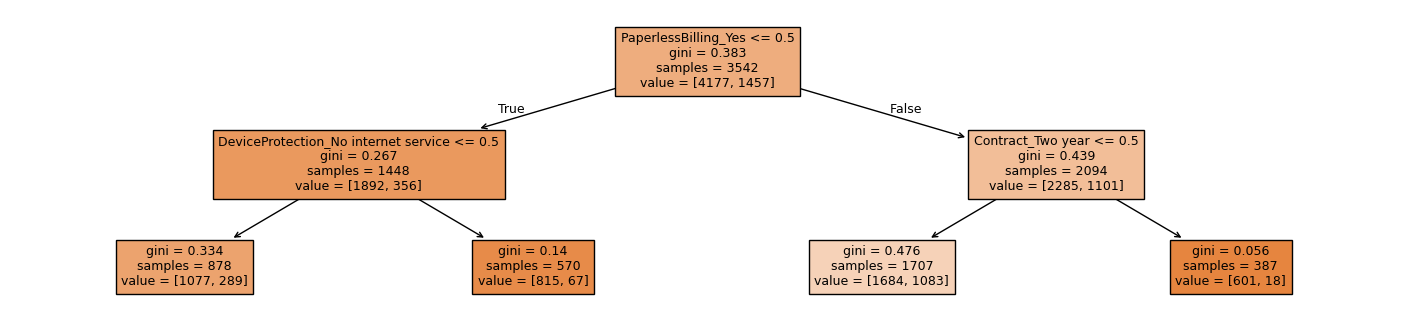

In [49]:
## TREE 1: plot 
plt.figure(figsize=(18,4))
plot_tree(rf.estimators_[0], feature_names=X_train.columns, filled = True, fontsize=9);

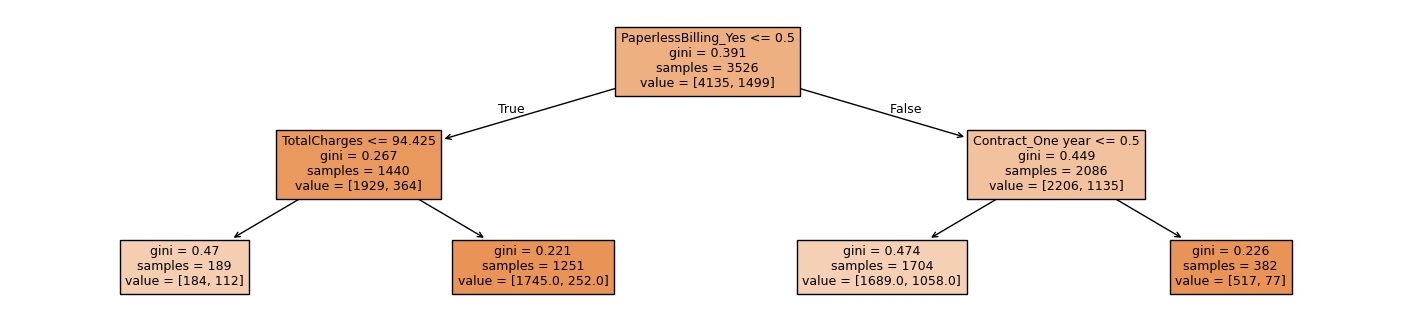

In [50]:
## TREE 2: plot 
plt.figure(figsize=(18,4))
plot_tree(rf.estimators_[1], feature_names=X_train.columns, filled = True, fontsize=9);

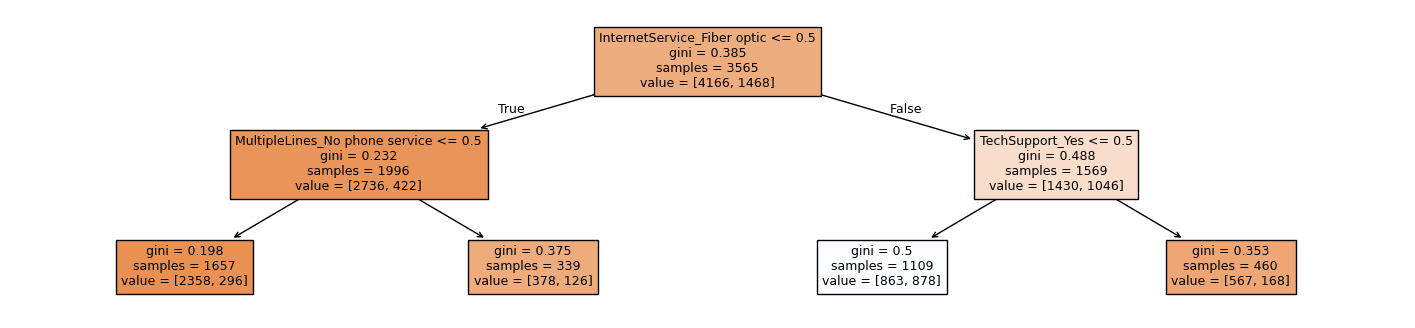

In [51]:
## TREE 3: plot 
plt.figure(figsize=(18,4))
plot_tree(rf.estimators_[2], feature_names=X_train.columns, filled = True, fontsize=9);

In [56]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_features=10,
    random_state=591,
    n_jobs=-1,
    oob_score=True
)
rf.fit(X_train, y_train)

print('Random forest test accuracy:', round(rf.score(X_test, y_test), 4))
print('Random forest OOB accuracy:', round(rf.oob_score_, 4))

Random forest test accuracy: 0.7864
Random forest OOB accuracy: 0.7918


**Practice 8A:** If the encoded data has 30 predictors, about how many are considered at each random-forest split with `max_features='sqrt'`? How is this different from ordinary bagging?

**Your answer:**

In [ ]:
# Inspect how many predictors are in the encoded data
print('Number of predictors:', X.shape[1])
print('Approx. candidates per split:', int(np.sqrt(X.shape[1])))

## 9. Compare the models

We will compare **test accuracy** and the confusion matrices. A model can have good accuracy while missing customers who actually churn. In a retention application, **recall for churners** may also matter.

In [57]:
# Compare test accuracies
results = pd.DataFrame({
    'Model': ['Single tree', 'Bagging (100 trees)', 'Random forest'],
    'Test Accuracy': [
        accuracy_score(y_test, dt.predict(X_test)),
        accuracy_score(y_test, bag100.predict(X_test)),
        accuracy_score(y_test, rf.predict(X_test))
    ]
})
results

,Model,Test Accuracy
0,Single tree,0.784244
1,Bagging (100 trees),0.772179
2,Random forest,0.786373


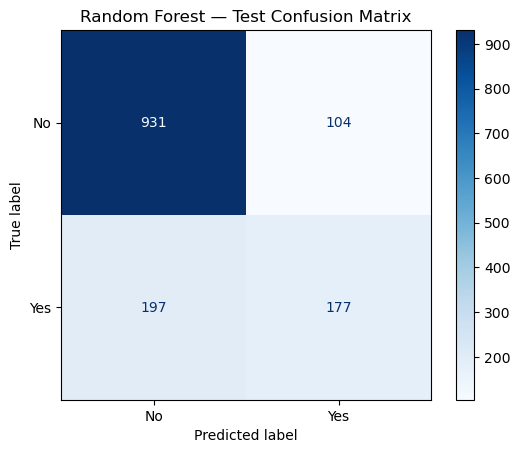

In [58]:
# Random forest confusion matrix
ConfusionMatrixDisplay.from_estimator(
    rf, X_test, y_test, display_labels=['No', 'Yes'], cmap='Blues'
)
plt.title('Random Forest — Test Confusion Matrix')
plt.show()

**Practice 9A:** Which model would you choose based on test accuracy? Is accuracy sufficient for deciding which customers should receive retention offers? What other measure from Module 4 could help?

**Your answer:**

## 10. Variable importance

`feature_importances_` ranks predictors by their contribution to reducing impurity across the forest. It is **not evidence of causation**. Interpret the encoded predictors, which may include dummy variables.

In [59]:
## VARIABLE IMPORTANCE
#### ranks each predictor according to the impurity decrease

importance = pd.DataFrame({
    'Variable': X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

importance.head(10)

,Variable,Importance
3,TotalCharges,0.208176
2,MonthlyCharges,0.176289
1,tenure,0.175053
10,InternetService_Fiber optic,0.063534
28,PaymentMethod_Electronic check,0.039311
25,Contract_Two year,0.030389
4,gender_Male,0.025236
26,PaperlessBilling_Yes,0.025025
5,Partner_Yes,0.021541
13,OnlineSecurity_Yes,0.020609


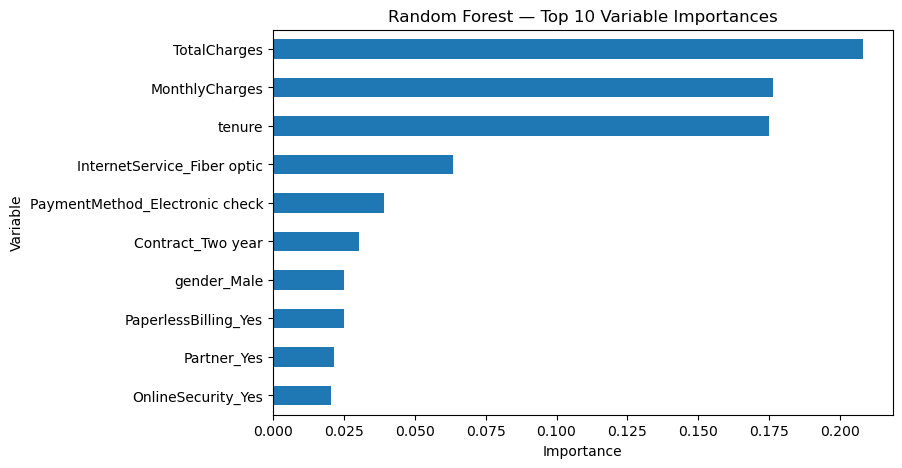

In [60]:
importance.head(10).sort_values('Importance').plot(
    x='Variable', y='Importance', kind='barh', legend=False, figsize=(8, 5)
)
plt.title('Random Forest — Top 10 Variable Importances')
plt.xlabel('Importance')
plt.show()

### Final challenge — Retention manager briefing

In **4–5 sentences**, explain:

1. Why do bagging and random forests fit more than one tree?
2. What additional randomness is introduced by random forests?
3. Which model had the strongest test accuracy in your run?
4. What was one important predictor, and what should you **not** conclude from importance alone?

**Your briefing:**

## Optional exploration (only if time permits)

Change `n_estimators=100` to `20` or `200` in the random-forest example and fit again. Do the test and OOB scores change? Why could more trees stabilize the ensemble without guaranteeing an improvement on every test set?

**Exit ticket:** Explain the difference between one tree, bagging, and random forests in one sentence each.